# 02 · Análise inferencial

O notebook 01 descreveu os dados. Aqui fazemos duas perguntas que pedem **inferência estatística**,
isto é, separar padrão real de acaso e de confundimento:

1. **A temperatura está associada aos casos de dengue além do que a época do ano já explica?**
2. **O modelo de previsão é significativamente melhor que o baseline, ou a diferença pode ser acaso?**

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from radar_dengue import style
style.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
import statsmodels.api as sm
import statsmodels.formula.api as smf

raw = pd.read_parquet("data/raw/infodengue_sp.parquet").sort_values(["geocode", "data_iniSE"])

## Pergunta 1 · Temperatura e dengue

### Desenho

- **Unidade:** município-semana, nos **82 municípios com mais de 100 mil habitantes** (nos
  menores, os muitos zeros e a incidência instável dificultam a estimação), de 2015 a 2025.
- **Desfecho:** casos notificados na semana.
- **Modelo:** regressão **binomial negativa**, adequada a contagens sobredispersas (variância
  44 vezes a média, notebook 01), com a população como *offset*. Assim os coeficientes viram
  **razões de taxas de incidência (IRR)**: IRR = 1,10 significa 10% mais casos por habitante.
- **Exposição:** temperatura média das 4 semanas que terminam *L* semanas antes da semana do desfecho.
- **Controles:**
  - época do ano (seno e cosseno da semana), o confundidor principal;
  - efeito fixo de **ano** (anos epidêmicos têm causas, como sorotipo e imunidade, que não medimos);
  - efeito fixo de **município** (diferenças permanentes entre cidades);
  - umidade média.
- **Incerteza:** erros-padrão robustos agrupados por município, porque semanas da mesma cidade não
  são independentes (e, como robustez, agrupados também por semana).

In [2]:
d = raw[raw["pop"] > 100e3].copy()
g = d.groupby("geocode")
for c in ["tempmed", "umidmed"]:
    d[c] = g[c].transform(lambda s: s.ffill().bfill())
sem = d["SE"] % 100
d["sen"] = np.sin(2 * np.pi * sem / 52); d["cos"] = np.cos(2 * np.pi * sem / 52)
d["ano"] = (d["SE"] // 100).astype(str)
d = d[d["SE"] // 100 < 2026]
grupos = pd.factorize(d["geocode"])[0]

def ajustar(lag, alpha=1.0, com_sazonalidade=True, dados=None):
    x = (dados if dados is not None else d).copy()
    gg = x.groupby("geocode")
    x["temp"] = gg["tempmed"].transform(lambda s: s.shift(lag).rolling(4).mean())
    x["umid"] = gg["umidmed"].transform(lambda s: s.shift(lag).rolling(4).mean())
    x = x.dropna(subset=["temp", "umid"])
    termos = "temp + umid + C(ano) + C(geocode)" + (" + sen + cos" if com_sazonalidade else "")
    m = smf.glm(f"casos ~ {termos}", x, family=sm.families.NegativeBinomial(alpha=alpha),
                offset=np.log(x["pop"])).fit(cov_type="cluster",
                                              cov_kwds={"groups": pd.factorize(x["geocode"])[0]})
    lo, hi = np.exp(m.conf_int().loc["temp"])
    return {"defasagem": lag, "IRR por +1 °C": np.exp(m.params["temp"]), "IC 95% inf": lo,
            "IC 95% sup": hi, "p-valor": m.pvalues["temp"], "n": int(m.nobs)}

print(f"{d['geocode'].nunique()} municípios, {len(d):,} semanas")

82 municípios, 46,342 semanas


### Primeiro, o modelo ingênuo: sem controlar a época do ano

In [3]:
ingenuo = pd.DataFrame([ajustar(L, com_sazonalidade=False) for L in [0, 4, 8, 12]]).set_index("defasagem")
ingenuo

,IRR por +1 °C,IC 95% inf,IC 95% sup,p-valor,n
defasagem,,,,,
0,1.19,1.18,1.21,0.00,46096
4,1.30,1.27,1.32,0.00,45768
8,1.31,1.29,1.34,0.00,45440
12,1.29,1.26,1.31,0.00,45112


Sem controlar a sazonalidade, cada grau a mais de temperatura aparece associado a um **aumento grande
de casos** semanas depois, com p-valor praticamente zero. É o que a correlação do notebook 01
sugeria. Mas esse modelo compara verão com inverno, e muita coisa além da temperatura muda entre as
estações.

### Agora, controlando a época do ano

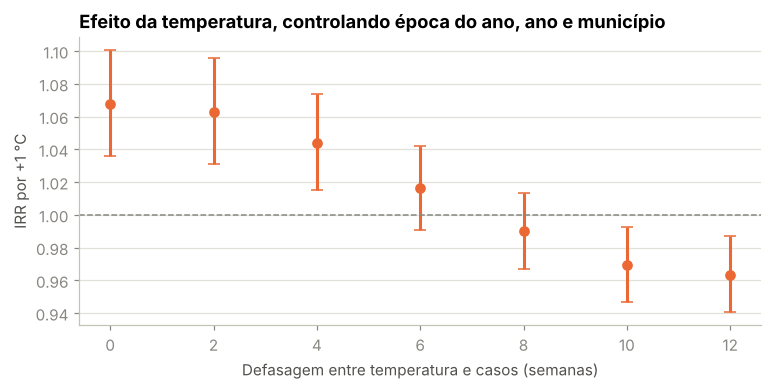

,IRR por +1 °C,IC 95% inf,IC 95% sup,p-valor,n
defasagem,,,,,
0,1.07,1.04,1.10,0.00,46096
2,1.06,1.03,1.10,0.00,45932
4,1.04,1.01,1.07,0.00,45768
6,1.02,0.99,1.04,0.21,45604
8,0.99,0.97,1.01,0.39,45440
10,0.97,0.95,0.99,0.01,45276
12,0.96,0.94,0.99,0.00,45112


In [4]:
ajustado = pd.DataFrame([ajustar(L) for L in [0, 2, 4, 6, 8, 10, 12]]).set_index("defasagem")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.errorbar(ajustado.index, ajustado["IRR por +1 °C"],
            yerr=[ajustado["IRR por +1 °C"] - ajustado["IC 95% inf"], ajustado["IC 95% sup"] - ajustado["IRR por +1 °C"]],
            fmt="o", color=style.PREVISTO, capsize=4)
ax.axhline(1, color="#898781", linewidth=1, linestyle="--")
ax.set_xlabel("Defasagem entre temperatura e casos (semanas)"); ax.set_ylabel("IRR por +1 °C")
ax.set_title("Efeito da temperatura, controlando época do ano, ano e município")
plt.show()
ajustado

**O efeito encolhe muito.** Controlando a época do ano, o ano e o município:

- nas defasagens **curtas (0 a 4 semanas)**, cada grau a mais está associado a **4% a 7% mais casos**,
  contra quase 30% no modelo ingênuo;
- na defasagem de **8 semanas**, onde a correlação bruta era máxima, **o efeito desaparece**
  (IRR 0,99, intervalo de 0,97 a 1,01);
- em **10 a 12 semanas** a estimativa fica levemente abaixo de 1, provavelmente porque o seno e o
  cosseno não capturam com perfeição o formato da estação. Não é um efeito protetor plausível.

**Como interpretar:** a maior parte da relação entre temperatura e dengue vista no notebook 01 era
**confundimento sazonal**: a temperatura cria a estação da dengue, e a sazonalidade já captura isso.
Dentro da mesma época do ano, semanas mais quentes que o normal têm um efeito real, mas **pequeno e
de curto prazo**. A associação na defasagem zero deve ser lida com cautela, porque calor e casos na
mesma semana podem ter causas comuns.

Isso é coerente com o notebook 03, em que a temperatura tem peso pequeno no modelo de previsão.

### Robustez: o resultado depende do parâmetro de dispersão?

In [5]:
rob = pd.DataFrame([{**ajustar(L, alpha=a), "alpha": a} for L in [2, 8] for a in [0.5, 1.0, 2.0]])
rob.set_index(["defasagem", "alpha"])[["IRR por +1 °C", "IC 95% inf", "IC 95% sup", "p-valor"]]

IRR por +1 °C  IC 95% inf  IC 95% sup  p-valor
defasagem alpha                                                
2         0.50            1.07        1.03        1.10     0.00
          1.00            1.06        1.03        1.10     0.00
          2.00            1.06        1.03        1.09     0.00
8         0.50            0.99        0.97        1.01     0.44
          1.00            0.99        0.97        1.01     0.39
          2.00            0.99        0.97        1.01     0.36

As estimativas praticamente não mudam com o parâmetro de dispersão da binomial negativa, tanto na
defasagem curta (efeito pequeno e positivo) quanto na de 8 semanas (sem efeito).

### Robustez: e se as semanas também forem correlacionadas entre municípios?

Os erros-padrão acima são agrupados por município, o que trata a correlação ao longo do tempo dentro
de cada cidade. Mas uma semana de calor atípico afeta todas as cidades ao mesmo tempo, e isso também
gera correlação. Refazemos com **agrupamento em duas dimensões** (município e semana).

In [6]:
def ajustar_2vias(lag):
    x = d.copy()
    gg = x.groupby("geocode")
    x["temp"] = gg["tempmed"].transform(lambda s: s.shift(lag).rolling(4).mean())
    x["umid"] = gg["umidmed"].transform(lambda s: s.shift(lag).rolling(4).mean())
    x = x.dropna(subset=["temp", "umid"]).reset_index(drop=True)
    grupos2 = np.column_stack([pd.factorize(x["geocode"])[0], pd.factorize(x["data_iniSE"])[0]])
    m = smf.glm("casos ~ temp + umid + C(ano) + C(geocode) + sen + cos", x,
                family=sm.families.NegativeBinomial(alpha=1.0), offset=np.log(x["pop"])).fit(
        cov_type="cluster", cov_kwds={"groups": grupos2})
    lo, hi = np.exp(m.conf_int().loc["temp"])
    return {"defasagem": lag, "IRR por +1 °C": np.exp(m.params["temp"]), "IC 95% inf": lo,
            "IC 95% sup": hi, "p-valor": m.pvalues["temp"]}

pd.DataFrame([ajustar_2vias(L) for L in [0, 2, 4, 8]]).set_index("defasagem")

,IRR por +1 °C,IC 95% inf,IC 95% sup,p-valor
defasagem,,,,
0,1.07,1.02,1.11,0.00
2,1.06,1.02,1.11,0.00
4,1.04,1.00,1.08,0.03
8,0.99,0.96,1.02,0.56


Os intervalos ficam um pouco mais largos, como esperado, mas **a conclusão não muda**: efeito
pequeno e positivo nas defasagens curtas (ainda significativo até 4 semanas) e nenhum efeito em 8
semanas.

**Limitações desta análise:** é um estudo observacional. Não medimos sorotipo circulante, imunidade da
população nem ações de controle do mosquito, que variam entre anos e cidades. Os efeitos fixos de ano
e município absorvem parte disso, mas não tudo. A temperatura vem das estações usadas pelo InfoDengue,
não de uma medição dentro de cada bairro.

## Pergunta 2 · O modelo é significativamente melhor que o baseline?

No notebook 03, o modelo de produção (LightGBM com perda de Poisson) erra menos que o baseline ingênuo ("os casos daqui a *h* semanas
serão iguais aos de hoje"). Mas o período de teste tem uma epidemia muito atípica: a diferença poderia
vir de poucas semanas extremas?

Usamos o **teste de Diebold-Mariano**, o padrão para comparar previsões:

1. Para cada semana, calculamos a diferença média de erro entre os dois métodos, considerando todos os municípios.
2. Testamos se a média dessa diferença ao longo das semanas é zero.
3. Como erros de semanas vizinhas são correlacionados, usamos erros-padrão de **Newey-West (HAC)**.

Fazemos o teste em duas escalas:
- **erro absoluto em casos:** dominado pelas cidades grandes e pelos picos;
- **erro absoluto em log(1 + casos):** dá peso parecido a todos os municípios.

In [7]:
from radar_dengue.features import FEATURES, add_targets, build_features
from radar_dengue.model import fit_central, predict_central, split

base = add_targets(build_features(raw), [1, 2, 3, 4])

def dm_test(diff_por_semana, maxlags=8):
    ols = sm.OLS(diff_por_semana.values, np.ones(len(diff_por_semana))).fit(
        cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return ols.params[0], ols.bse[0], ols.pvalues[0]

linhas = []
for h in [1, 2, 3, 4]:
    tr, te = split(base, h)
    y = f"y_h{h}"
    m = fit_central(tr, h)   # o modelo de produção: LightGBM com perda de Poisson
    pred_log = np.log1p(predict_central(m, te))
    real_log, naive_log = te[y].to_numpy(), te["log_casos_lag0"].to_numpy()
    real, pred, naive = np.expm1(real_log), np.expm1(pred_log).clip(0), np.expm1(naive_log)
    semana = te["data_iniSE"].values
    for escala, dif in [("casos", np.abs(real - pred) - np.abs(real - naive)),
                        ("log", np.abs(real_log - pred_log) - np.abs(real_log - naive_log))]:
        serie = pd.Series(dif).groupby(semana).mean()
        media, ep, p = dm_test(serie)
        linhas.append({"horizonte": h, "escala": escala, "diferença média (modelo − baseline)": media,
                       "erro-padrão HAC": ep, "p-valor": p,
                       "% semanas em que o modelo erra menos": (serie < 0).mean() * 100,
                       "semanas": len(serie)})
dm = pd.DataFrame(linhas).set_index(["escala", "horizonte"]).sort_index()
dm

diferença média (modelo − baseline)  erro-padrão HAC  \
escala horizonte                                                         
casos  1                                        -1.74             0.95   
       2                                        -4.42             2.35   
       3                                        -8.21             3.91   
       4                                       -10.86             5.56   
log    1                                        -0.01             0.01   
       2                                        -0.03             0.01   
       3                                        -0.06             0.02   
       4                                        -0.09             0.03   

                  p-valor  % semanas em que o modelo erra menos  semanas  
escala horizonte                                                          
casos  1             0.07                                 73.24      142  
       2             0.06                                 66.67      141  
       3             0.04                                 70.71      140  
       4             0.05                                 69.06      139  
log    1             0.07                                 68.31      142  
       2             0.01                                 68.79      141  
       3             0.01                                 68.57      140  
       4             0.01                                 66.91      139

**Leitura:**

- **Com 2 a 4 semanas de antecedência, a melhora é estatisticamente significativa** na escala log
  (p entre 0,007 e 0,015): consistente entre os municípios, não concentrada em algumas cidades. Em
  número absoluto de casos, ela é significativa com 3 semanas e fica no limite com 2 e 4
  (p entre 0,04 e 0,06).
- **Com 1 semana, o ganho é pequeno e não é significativo** (p ≈ 0,07 nas duas escalas). Faz
  sentido: no curto prazo a epidemia tem muita inércia, e repetir a semana atual já é quase o melhor
  que se pode fazer.
- Em número absoluto de casos, o erro é dominado por poucas semanas de pico da epidemia de 2024 nas
  cidades grandes; com tão poucos eventos extremos, a incerteza é alta.

**Conclusão honesta:** o modelo é melhor de forma estatisticamente comprovada justamente onde ele é
útil, com 2 a 4 semanas de antecedência. Na semana seguinte, ele empata com o baseline. Afirmações
mais fortes, como "melhor nos picos", exigiriam mais epidemias no período de avaliação, algo que só o
monitoramento contínuo vai fornecer.

## Resumo

| Pergunta | Resposta |
|---|---|
| Temperatura aumenta a dengue além da sazonalidade? | Pouco: cerca de 4% a 7% mais casos por grau, só no curto prazo (0 a 4 semanas). A correlação forte vista na descritiva era quase toda sazonal. |
| O modelo supera o baseline? | Sim, com significância estatística com 2 a 4 semanas de antecedência. Com 1 semana, empata (p ≈ 0,07). |
| Supera também em número absoluto de casos? | Sim na média; com significância só com 3 semanas e no limite com 2 e 4. |